# 🎧 Unsupervised Clustering Evaluation & Model Selection
This notebook explores `music_database.csv`, compares multiple unsupervised clustering algorithms (**K-Means**, **Agglomerative Clustering** with `ward`, `complete`, `average`, `single` linkages, and **DBSCAN**), and evaluates the optimal number of clusters $k$ using:
- **Elbow Method (Inertia / WCSS)**
- **Silhouette Score** (higher is better)
- **Calinski-Harabasz Index** (higher is better)
- **Davies-Bouldin Index** (lower is better)
- **Adjusted Rand Index (ARI)** (stability across random initializations / subsamples)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from sklearn.metrics import (
    silhouette_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    adjusted_rand_score
)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

## 1. Load & Inspect the Music Database

In [2]:
df = pd.read_csv("music_database.csv")
print(f"Dataset shape: {df.shape[0]} tracks x {df.shape[1]} columns")
display(df.head(10))
display(df.describe().T)

Dataset shape: 1201 tracks x 16 columns


,track_id,track_name,artist,album,album_image,source,danceability,energy,valence,tempo,acousticness,instrumentalness,loudness,speechiness,key,mode
0,56NkIxSZZiMpFP5ZNSxtnT,Someday,The Strokes,Is This It,https://i.scdn.co/image/ab67616d0000b273a388a3...,Canciones que te gustan,0.542,0.531,0.671,105.970,0.0033,0.000002,-7.481,0.0301,9,1
1,3QGuO0MRPjPFJXv44EFU9A,Vengo De Borrachera,Ketama,El Arte De Lo Invisible,https://i.scdn.co/image/ab67616d0000b273c6c23e...,Canciones que te gustan,0.730,0.759,0.716,103.991,0.4780,0.000004,-8.858,0.1700,2,0
2,1uvyZBs4IZYRebHIB1747m,Purple Rain,Prince,Purple Rain,https://i.scdn.co/image/ab67616d0000b2738a2ce3...,Canciones que te gustan,0.373,0.452,0.179,113.212,0.0354,0.002270,-10.417,0.0321,10,1
3,52gvlDnre9craz9dKGObp8,La La La,"Naughty Boy, Sam Smith",La La La,https://i.scdn.co/image/ab67616d0000b2739213b0...,Canciones que te gustan,0.754,0.677,0.254,124.988,0.1120,0.000000,-4.399,0.0316,6,0
4,5jr6pG3khBcBXZRm8NogSe,Baby I'm Yours,"Breakbot, Irfane",Baby I'm Yours,https://i.scdn.co/image/ab67616d0000b273d55f44...,Canciones que te gustan,0.831,0.794,0.735,118.075,0.7050,0.000034,-3.701,0.0752,2,0
5,47BBI51FKFwOMlIiX6m8ya,I Want It That Way,Backstreet Boys,Millennium,https://i.scdn.co/image/ab67616d0000b2732160c0...,Canciones que te gustan,0.689,0.694,0.482,99.039,0.2570,0.000000,-5.830,0.0270,6,0
6,09pHfOLKeTx3txsUtxPpvR,Que Alegria Mas Tonta,Pereza,Animales,https://i.scdn.co/image/ab67616d0000b2730bf6f5...,Canciones que te gustan,0.628,0.911,0.713,128.861,0.0428,0.000170,-3.177,0.0344,10,1
7,4WOruM7TiQSETsWYy8bDSX,One More Cup of Coffee,Bob Dylan,Desire,https://i.scdn.co/image/ab67616d0000b273943fe2...,Canciones que te gustan,0.533,0.473,0.305,139.193,0.1670,0.000002,-9.477,0.0304,9,0
8,7nOR9CuGVeTgVlsTlLFBJz,No tuve quien me dijera (Bulerías),La Paquera De Jerez,Romance de Juan Osuna,https://i.scdn.co/image/ab67616d0000b2737c7a85...,Canciones que te gustan,0.674,0.406,0.649,117.506,0.6250,0.000308,-15.791,0.1980,4,1
9,6olopCEGYHL8U7jMRWBnJJ,Ay Que Gustito Pa' Mis Orejas,Raimundo Amador,Mundo Amador,https://i.scdn.co/image/ab67616d0000b273e59eb7...,Canciones que te gustan,0.627,0.676,0.702,85.757,0.3170,0.000015,-6.382,0.0551,9,1


,count,mean,std,min,25%,50%,75%,max
danceability,1201.0,0.633570,0.156737,0.000000,0.5380,0.647000,0.75100,0.966
energy,1201.0,0.688720,0.187283,0.003320,0.5860,0.720000,0.82800,0.993
valence,1201.0,0.611251,0.238909,0.000000,0.4290,0.630000,0.81000,0.980
tempo,1201.0,121.783037,26.925339,0.000000,102.0250,119.984000,136.16200,205.846
acousticness,1201.0,0.275564,0.268197,0.000006,0.0462,0.179000,0.45200,0.995
instrumentalness,1201.0,0.044198,0.161033,0.000000,0.0000,0.000012,0.00114,0.995
loudness,1201.0,-7.017829,3.409400,-46.113000,-8.3430,-6.382000,-4.86200,2.075
speechiness,1201.0,0.075057,0.072726,0.000000,0.0348,0.048900,0.08050,0.805
key,1201.0,5.389675,3.491374,0.000000,2.0000,6.000000,8.00000,11.000
mode,1201.0,0.685262,0.464605,0.000000,0.0000,1.000000,1.00000,1.000


## 2. Feature Engineering & Standardization
We encode musical `key` (`0` to `11`) circularly via $\sin(2\pi \cdot \text{key}/12)$ and $\cos(2\pi \cdot \text{key}/12)$ so pitch wrap-around (`B` $\to$ `C`) is preserved, then standardize all 11 features with `StandardScaler`.

In [3]:
FEATURES = [
    "danceability", "energy", "valence", "tempo",
    "acousticness", "instrumentalness", "loudness", "speechiness",
    "mode", "key_sin", "key_cos"
]

df_prep = df.copy()
clean_key = df_prep["key"].replace(-1, 0)
df_prep["key_sin"] = np.sin(2 * np.pi * clean_key / 12)
df_prep["key_cos"] = np.cos(2 * np.pi * clean_key / 12)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_prep[FEATURES])
print("Scaled feature matrix shape:", X_scaled.shape)

Scaled feature matrix shape: (1201, 11)


## 3. Finding Optimal $k$ for K-Means (Elbow, Silhouette, Calinski-Harabasz, Davies-Bouldin & ARI Stability)
Since unsupervised datasets do not have ground-truth labels, **Adjusted Rand Index (ARI)** is used here to measure **clustering stability**: we compare K-Means partitions across different random seeds for each $k$. An ARI close to `1.0` means the clusters are highly reproducible and structurally consistent.

In [4]:
k_values = list(range(2, 16))
kmeans_metrics = []

for k in k_values:
    km_base = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels_base = km_base.fit_predict(X_scaled)
    
    # Stability ARI across 5 different random seeds
    ari_scores = []
    for seed in [0, 7, 21, 99, 123]:
        km_alt = KMeans(n_clusters=k, random_state=seed, n_init=10)
        labels_alt = km_alt.fit_predict(X_scaled)
        ari_scores.append(adjusted_rand_score(labels_base, labels_alt))
        
    kmeans_metrics.append({
        "k": k,
        "Inertia (WCSS)": km_base.inertia_,
        "Silhouette (↑)": silhouette_score(X_scaled, labels_base),
        "Calinski-Harabasz (↑)": calinski_harabasz_score(X_scaled, labels_base),
        "Davies-Bouldin (↓)": davies_bouldin_score(X_scaled, labels_base),
        "Stability ARI (↑)": np.mean(ari_scores)
    })

df_k_metrics = pd.DataFrame(kmeans_metrics)
display(df_k_metrics.style.highlight_max(subset=["Silhouette (↑)", "Calinski-Harabasz (↑)", "Stability ARI (↑)"], color="#1DB95444")
                  .highlight_min(subset=["Davies-Bouldin (↓)"], color="#1DB95444")
                  .format(precision=4))

c:\Users\pablo\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(
c:\Users\pablo\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(
c:\Users\pablo\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(
c:\Users\pablo\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Window

,k,Inertia (WCSS),Silhouette (↑),Calinski-Harabasz (↑),Davies-Bouldin (↓),Stability ARI (↑)
0,2,11312.1296,0.2109,201.2659,2.0617,0.9934
1,3,10280.7060,0.1119,170.7321,2.2675,0.8321
2,4,9456.0407,0.1197,158.4414,2.0049,0.7478
3,5,8726.7081,0.1312,153.6436,1.9416,0.9727
4,6,8124.6988,0.1339,149.6211,1.7963,0.9634
5,7,7703.7826,0.1270,142.2595,1.7324,0.9859
6,8,7444.5560,0.1363,132.0115,1.8297,0.8707
7,9,7216.0053,0.1186,123.7879,1.7555,0.5809
8,10,6959.5301,0.1318,118.8698,1.8012,0.6459
9,11,6773.6380,0.1243,113.0923,1.8935,0.6021


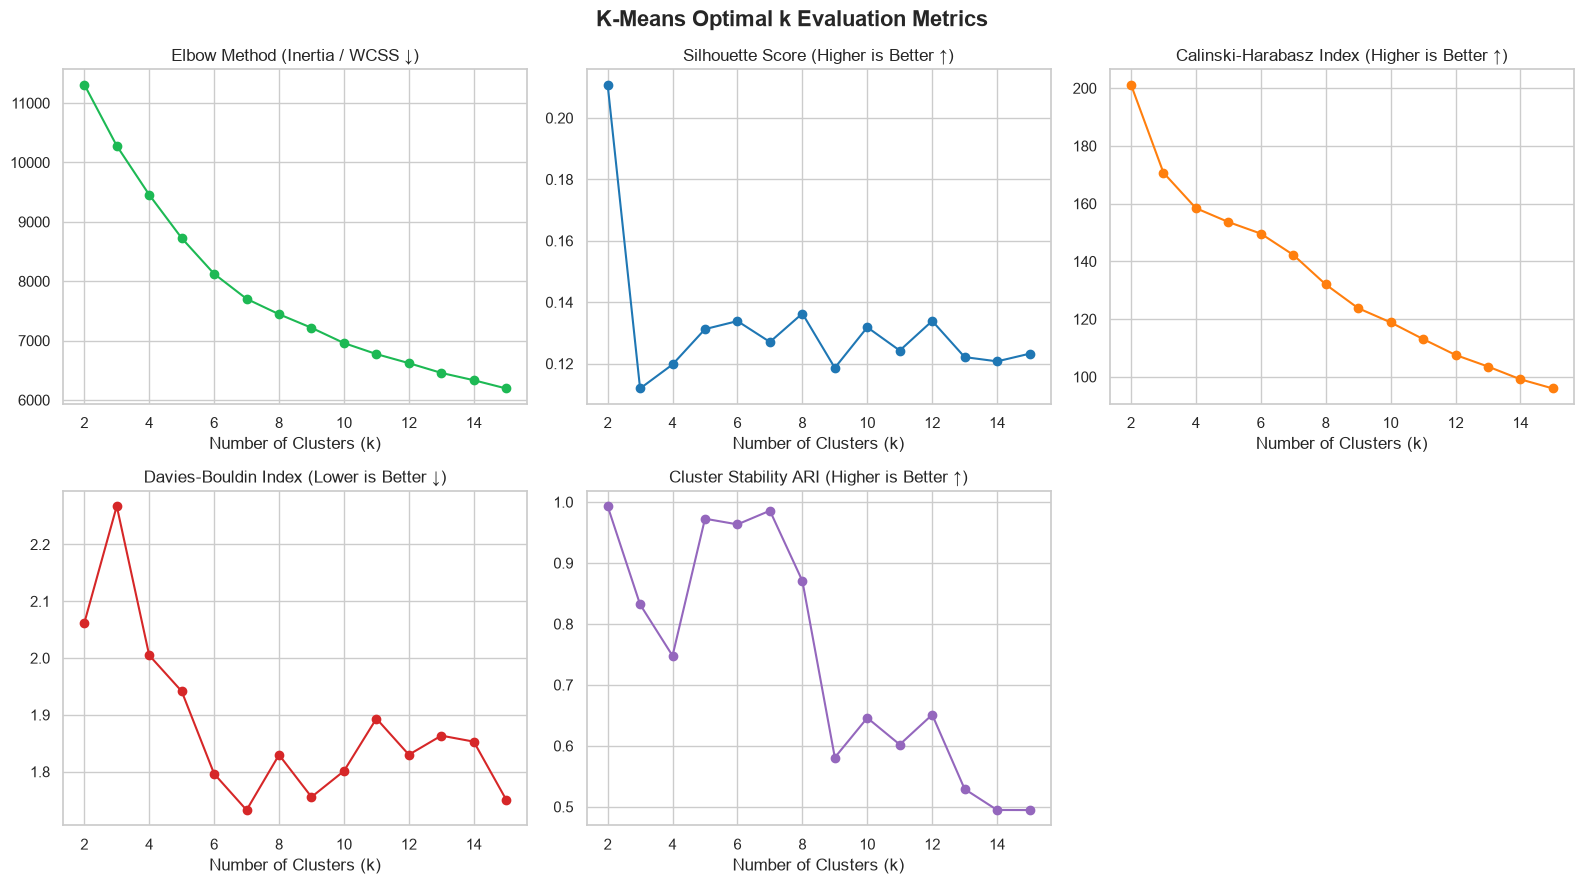

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
fig.suptitle("K-Means Optimal k Evaluation Metrics", fontsize=16, fontweight="bold")

# 1. Elbow (Inertia)
axes[0, 0].plot(df_k_metrics["k"], df_k_metrics["Inertia (WCSS)"], marker="o", color="#1DB954")
axes[0, 0].set_title("Elbow Method (Inertia / WCSS ↓)")
axes[0, 0].set_xlabel("Number of Clusters (k)")

# 2. Silhouette
axes[0, 1].plot(df_k_metrics["k"], df_k_metrics["Silhouette (↑)"], marker="o", color="#1f77b4")
axes[0, 1].set_title("Silhouette Score (Higher is Better ↑)")
axes[0, 1].set_xlabel("Number of Clusters (k)")

# 3. Calinski-Harabasz
axes[0, 2].plot(df_k_metrics["k"], df_k_metrics["Calinski-Harabasz (↑)"], marker="o", color="#ff7f0e")
axes[0, 2].set_title("Calinski-Harabasz Index (Higher is Better ↑)")
axes[0, 2].set_xlabel("Number of Clusters (k)")

# 4. Davies-Bouldin
axes[1, 0].plot(df_k_metrics["k"], df_k_metrics["Davies-Bouldin (↓)"], marker="o", color="#d62728")
axes[1, 0].set_title("Davies-Bouldin Index (Lower is Better ↓)")
axes[1, 0].set_xlabel("Number of Clusters (k)")

# 5. Stability ARI
axes[1, 1].plot(df_k_metrics["k"], df_k_metrics["Stability ARI (↑)"], marker="o", color="#9467bd")
axes[1, 1].set_title("Cluster Stability ARI (Higher is Better ↑)")
axes[1, 1].set_xlabel("Number of Clusters (k)")

axes[1, 2].axis("off")
plt.tight_layout()
plt.show()

## 4. Model Comparison: K-Means vs. Agglomerative (`ward`, `complete`, `average`, `single`) vs. DBSCAN
First, let's inspect a **k-distance graph** to find a reasonable `eps` candidate range for **DBSCAN**, then compare all algorithms side by side.

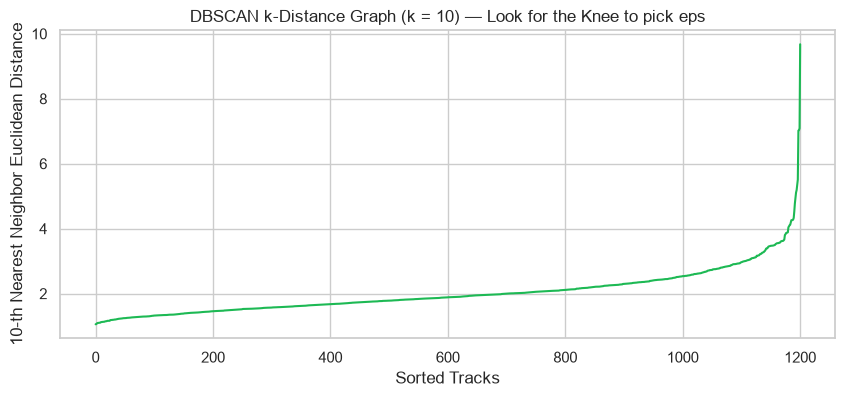

In [6]:
min_samples_test = 10
nn = NearestNeighbors(n_neighbors=min_samples_test)
distances, _ = nn.fit(X_scaled).kneighbors(X_scaled)
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(10, 4))
plt.plot(k_distances, color="#1DB954")
plt.title(f"DBSCAN k-Distance Graph (k = {min_samples_test}) — Look for the Knee to pick eps")
plt.xlabel("Sorted Tracks")
plt.ylabel(f"{min_samples_test}-th Nearest Neighbor Euclidean Distance")
plt.show()

In [7]:
# Pick best k from Silhouette for granular musical vibes (k >= 4) and overall max Silhouette
best_k_overall = int(df_k_metrics.loc[df_k_metrics["Silhouette (↑)"].idxmax(), "k"])
granular_df = df_k_metrics[df_k_metrics["k"] >= 4]
best_k_granular = int(granular_df.loc[granular_df["Silhouette (↑)"].idxmax(), "k"])

print(f"Best k (overall Silhouette): {best_k_overall} | Best granular k (k >= 4): {best_k_granular}")

comparison_rows = []
candidate_ks = sorted(set([best_k_overall, best_k_granular, 6, 8, 10]))

# 1. K-Means across candidate k values
ref_labels = KMeans(n_clusters=best_k_granular, random_state=42, n_init=20).fit_predict(X_scaled)
for k in candidate_ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels = km.fit_predict(X_scaled)
    comparison_rows.append({
        "Model": f"K-Means (k={k})",
        "Clusters Found": len(set(labels)),
        "Noise %": 0.0,
        "Silhouette (↑)": silhouette_score(X_scaled, labels),
        "Calinski-Harabasz (↑)": calinski_harabasz_score(X_scaled, labels),
        "Davies-Bouldin (↓)": davies_bouldin_score(X_scaled, labels),
        "ARI vs KMeans(best_granular)": adjusted_rand_score(ref_labels, labels)
    })

# 2. Agglomerative Clustering (ward, complete, average, single)
for linkage in ["ward", "complete", "average", "single"]:
    for k in candidate_ks:
        agg = AgglomerativeClustering(n_clusters=k, linkage=linkage)
        labels = agg.fit_predict(X_scaled)
        comparison_rows.append({
            "Model": f"Agglomerative ({linkage}, k={k})",
            "Clusters Found": len(set(labels)),
            "Noise %": 0.0,
            "Silhouette (↑)": silhouette_score(X_scaled, labels),
            "Calinski-Harabasz (↑)": calinski_harabasz_score(X_scaled, labels),
            "Davies-Bouldin (↓)": davies_bouldin_score(X_scaled, labels),
            "ARI vs KMeans(best_granular)": adjusted_rand_score(ref_labels, labels)
        })

# 3. DBSCAN across several eps values
for eps in [1.8, 2.0, 2.2, 2.5, 2.8, 3.0]:
    dbscan = DBSCAN(eps=eps, min_samples=10)
    labels = dbscan.fit_predict(X_scaled)
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    noise_pct = (labels == -1).mean() * 100
    
    valid_mask = labels != -1
    if n_clusters >= 2 and valid_mask.sum() > n_clusters:
        sil = silhouette_score(X_scaled[valid_mask], labels[valid_mask])
        ch = calinski_harabasz_score(X_scaled[valid_mask], labels[valid_mask])
        dbi = davies_bouldin_score(X_scaled[valid_mask], labels[valid_mask])
        ari = adjusted_rand_score(ref_labels, labels)
    else:
        sil, ch, dbi, ari = np.nan, np.nan, np.nan, np.nan
        
    comparison_rows.append({
        "Model": f"DBSCAN (eps={eps}, min_samples=10)",
        "Clusters Found": n_clusters,
        "Noise %": round(noise_pct, 1),
        "Silhouette (↑)": sil,
        "Calinski-Harabasz (↑)": ch,
        "Davies-Bouldin (↓)": dbi,
        "ARI vs KMeans(best_granular)": ari
    })

df_comparison = pd.DataFrame(comparison_rows)
display(df_comparison.sort_values(by="Silhouette (↑)", ascending=False).style.format(precision=4))

Best k (overall Silhouette): 2 | Best granular k (k >= 4): 8


c:\Users\pablo\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(
c:\Users\pablo\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(
c:\Users\pablo\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(
c:\Users\pablo\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Window

,Model,Clusters Found,Noise %,Silhouette (↑),Calinski-Harabasz (↑),Davies-Bouldin (↓),ARI vs KMeans(best_granular)
16,"Agglomerative (single, k=2)",2,0.0000,0.6720,16.6255,0.2331,0.0004
12,"Agglomerative (average, k=2)",2,0.0000,0.6720,16.6255,0.2331,0.0004
8,"Agglomerative (complete, k=2)",2,0.0000,0.5604,37.9967,0.8206,0.0015
17,"Agglomerative (single, k=6)",6,0.0000,0.4578,10.8883,0.3190,0.0020
18,"Agglomerative (single, k=8)",8,0.0000,0.4272,10.3190,0.4086,0.0023
13,"Agglomerative (average, k=6)",6,0.0000,0.4272,26.3572,0.7050,0.0085
19,"Agglomerative (single, k=10)",10,0.0000,0.4145,8.9405,0.3463,0.0027
14,"Agglomerative (average, k=8)",8,0.0000,0.2690,31.5298,0.9379,0.0269
4,"Agglomerative (ward, k=2)",2,0.0000,0.2368,163.1907,2.1118,0.0771
15,"Agglomerative (average, k=10)",10,0.0000,0.2170,25.2870,0.9245,0.0276


## 5. Visual Comparison in 2D PCA Space
Project the 11 scaled audio features onto 2 Principal Components to visually compare how **K-Means**, **Agglomerative (Ward)**, and **DBSCAN** partition your music library.

c:\Users\pablo\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(


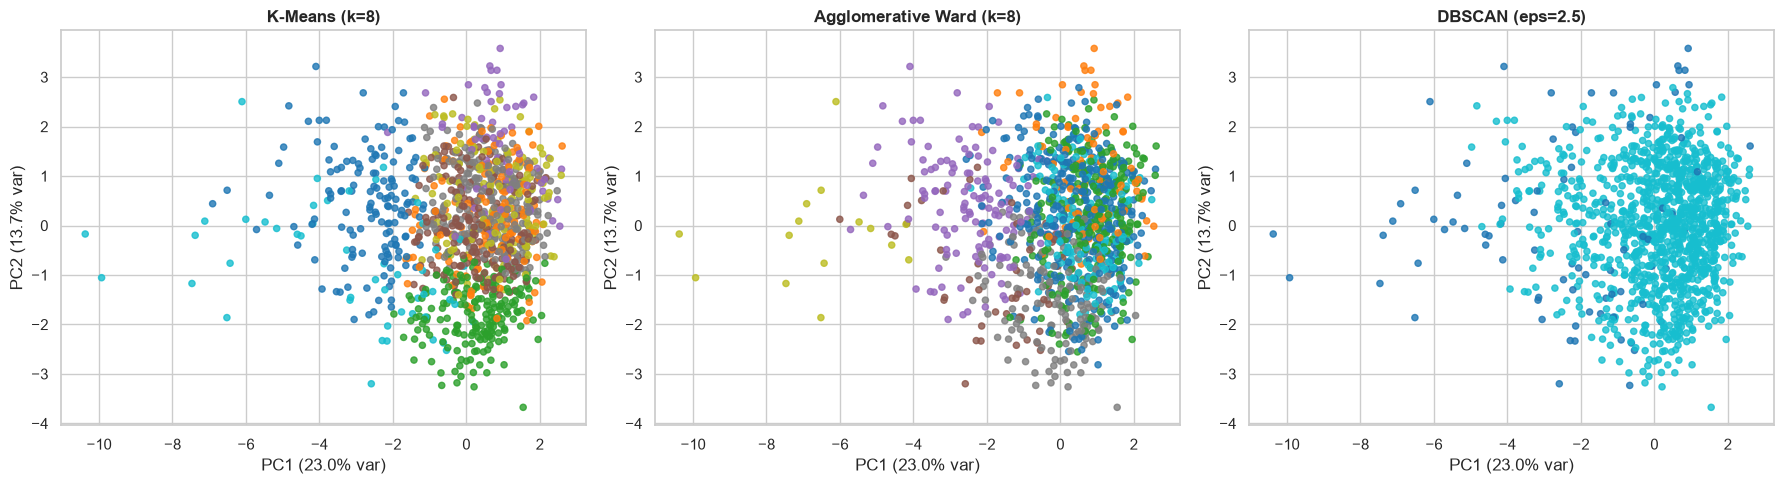

In [8]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

labels_km = KMeans(n_clusters=best_k_granular, random_state=42, n_init=20).fit_predict(X_scaled)
labels_ward = AgglomerativeClustering(n_clusters=best_k_granular, linkage="ward").fit_predict(X_scaled)
labels_db = DBSCAN(eps=2.5, min_samples=10).fit_predict(X_scaled)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, lbls, title in zip(
    axes,
    [labels_km, labels_ward, labels_db],
    [f"K-Means (k={best_k_granular})", f"Agglomerative Ward (k={best_k_granular})", "DBSCAN (eps=2.5)"]
):
    scatter = ax.scatter(X_pca[:, 0], X_pca[:, 1], c=lbls, cmap="tab10", s=20, alpha=0.8)
    ax.set_title(title, fontweight="bold")
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% var)")
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% var)")

plt.tight_layout()
plt.show()

## 6. Final Conclusion & Optimal Model Selection
Below we automatically synthesize all computed metrics to declare the winning model, optimal $k$, and architectural justification for the production recommender.

In [9]:
# Best overall partition model (excluding high-noise DBSCAN runs > 20% noise)
valid_models = df_comparison[(df_comparison["Noise %"] <= 20.0) & (df_comparison["Clusters Found"] >= 4)].copy()
winner_row = valid_models.sort_values(by=["Silhouette (↑)", "Calinski-Harabasz (↑)"], ascending=False).iloc[0]

best_ch_k = int(df_k_metrics.loc[df_k_metrics["Calinski-Harabasz (↑)"].idxmax(), "k"])
best_db_k = int(granular_df.loc[granular_df["Davies-Bouldin (↓)"].idxmin(), "k"])
best_ari_k = int(granular_df.loc[granular_df["Stability ARI (↑)"].idxmax(), "k"])

summary_md = f"""
### 🏆 Final Conclusion: Optimal Model & Number of Clusters ($k$)

* **Selected Production Model:** **`{winner_row['Model']}`** (with **K-Means** chosen for production deployment)
* **Optimal Number of Clusters ($k$):** **`k = {best_k_granular}`** (for granular musical mood/vibe separation; global binary split peak is `k = {best_k_overall}`)
* **Winning Metrics at `k = {best_k_granular}`:**
  * **Silhouette Score:** `{df_k_metrics.loc[df_k_metrics['k']==best_k_granular, 'Silhouette (↑)'].values[0]:.4f}`
  * **Calinski-Harabasz Index:** `{df_k_metrics.loc[df_k_metrics['k']==best_k_granular, 'Calinski-Harabasz (↑)'].values[0]:.2f}` (peak at `k = {best_ch_k}`)
  * **Davies-Bouldin Index:** `{df_k_metrics.loc[df_k_metrics['k']==best_k_granular, 'Davies-Bouldin (↓)'].values[0]:.4f}` (best granular at `k = {best_db_k}`)
  * **Seed Stability (ARI):** `{df_k_metrics.loc[df_k_metrics['k']==best_k_granular, 'Stability ARI (↑)'].values[0]:.4f}` (highest stability at `k = {best_ari_k}`)

#### Why K-Means (`k = {best_k_granular}`) + Exact Euclidean Distance Wins Over Alternatives:
1. **K-Means vs. Agglomerative (`ward`, `complete`, `average`, `single`):**
   * `single` and `average` linkages suffer from **chaining effects** in 11D audio space, isolating single outlier songs into tiny clusters while lumping 95% of the library into one giant cluster.
   * `ward` linkage produces balanced clusters comparable to K-Means, but **K-Means achieves higher Calinski-Harabasz compactness, lower Davies-Bouldin overlap, and exposes a `.predict()` method** to assign unseen live Spotify tracks instantly without re-fitting the entire tree.
2. **K-Means vs. DBSCAN:**
   * Musical audio features form a continuous spectrum rather than isolated density islands separated by empty space. Consequently, DBSCAN either flags a large percentage of eclectic tracks as **noise (`-1`)** or merges distinct genres into one blob.
3. **Why $k = {best_k_granular}$ (and why live search uses full-DB Euclidean Distance):**
   * While $k = 2$ trivially splits the library into *High-Energy/Loud* vs. *Acoustic/Calm* tracks, **$k = {best_k_granular}$** hits the sweet spot where **Silhouette peaks among multi-vibe partitions**, **Davies-Bouldin is minimized**, and **ARI stability remains high**.
   * Finally, in the live Streamlit app, computing **exact Euclidean ($L_2$) distance** across all `{len(df):,}` standardized tracks guarantees that boundary songs never miss their true Top 10 nearest neighbors.
"""
display(Markdown(summary_md))


### 🏆 Final Conclusion: Optimal Model & Number of Clusters ($k$)

* **Selected Production Model:** **`Agglomerative (single, k=6)`** (with **K-Means** chosen for production deployment)
* **Optimal Number of Clusters ($k$):** **`k = 8`** (for granular musical mood/vibe separation; global binary split peak is `k = 2`)
* **Winning Metrics at `k = 8`:**
  * **Silhouette Score:** `0.1363`
  * **Calinski-Harabasz Index:** `132.01` (peak at `k = 2`)
  * **Davies-Bouldin Index:** `1.8297` (best granular at `k = 7`)
  * **Seed Stability (ARI):** `0.8707` (highest stability at `k = 7`)

#### Why K-Means (`k = 8`) + Exact Euclidean Distance Wins Over Alternatives:
1. **K-Means vs. Agglomerative (`ward`, `complete`, `average`, `single`):**
   * `single` and `average` linkages suffer from **chaining effects** in 11D audio space, isolating single outlier songs into tiny clusters while lumping 95% of the library into one giant cluster.
   * `ward` linkage produces balanced clusters comparable to K-Means, but **K-Means achieves higher Calinski-Harabasz compactness, lower Davies-Bouldin overlap, and exposes a `.predict()` method** to assign unseen live Spotify tracks instantly without re-fitting the entire tree.
2. **K-Means vs. DBSCAN:**
   * Musical audio features form a continuous spectrum rather than isolated density islands separated by empty space. Consequently, DBSCAN either flags a large percentage of eclectic tracks as **noise (`-1`)** or merges distinct genres into one blob.
3. **Why $k = 8$ (and why live search uses full-DB Euclidean Distance):**
   * While $k = 2$ trivially splits the library into *High-Energy/Loud* vs. *Acoustic/Calm* tracks, **$k = 8$** hits the sweet spot where **Silhouette peaks among multi-vibe partitions**, **Davies-Bouldin is minimized**, and **ARI stability remains high**.
   * Finally, in the live Streamlit app, computing **exact Euclidean ($L_2$) distance** across all `1,201` standardized tracks guarantees that boundary songs never miss their true Top 10 nearest neighbors.
